# Tarea #8. Clasificación de rostros en tiempo real mediante redes neuronales convolucionales (CNN)

**Instituto Tecnológico de Culiacán**

**Materia:** Inteligencia Artificial

**Docente:** José Mario Ríos Félix

**Horario:** 6:00 a 7:00 p. m.

**Integrantes del equipo:**

- Kitzia Marisol Crespo Hernández. C23171148
- Emir Gabino Pérez Villarreal. 23170278
- Oscar Antonio Sánchez Lara. 23170334
- Jonathan Daniel Valencia. 23170373

## Objetivo de la práctica

Diseñar, entrenar e implementar un sistema de reconocimiento facial
en tiempo real mediante una red neuronal convolucional (CNN), que
permita procesar el video capturado por la cámara web y clasificar
los rostros detectados mediante el aprendizaje supervisado.

Se utiliza el dataset personalizado, recolectado y etiquetado en la
tarea 6, compuesto por 900 fotografías distribuidas en nueve clases,
correspondientes a los cuatro integrantes del equipo y cinco
personas famosas. Cada imagen contiene un rostro previamente
detectado y recortado en formato cuadrado.

Al finalizar el entrenamiento y la evaluación de los modelos,
se generan los siguientes archivos:

| Archivo | Contenido |
| --- | --- |
| `modelo_rostros.keras` | Modelo entrenado con el mejor desempeño. |
| `clases.json` | Nombres de las personas en el orden de clasificación del modelo. |

Ambos archivos se utilizan en el programa `reconocer-rostros.py`,
que integra OpenCV para detectar y clasificar los rostros en
tiempo real mediante la cámara web, mostrando el nombre de la
persona identificada y el porcentaje de confianza.

## I. Dataset y preprocesamiento de imágenes

### 1. Importación de librerías y dependencias

Se utiliza TensorFlow con Keras para construir y entrenar la red, OpenCV para
leer y redimensionar las imágenes, NumPy para manejar los arreglos y
Matplotlib para las gráficas.

In [1]:
import json
import logging
import os

# Reduce los mensajes de avisos de TensorFlow, hay que ponerlo antes de importarlo
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Desactiva las optimizaciones oneDNN para evitar sus avisos al iniciar
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Oculta el aviso de que no hay tarjeta de video y el de los reajustes internos
logging.getLogger("tensorflow").setLevel(logging.ERROR)

print("TensorFlow", tf.__version__)
print("Keras", keras.__version__)
print("OpenCV", cv2.__version__)

TensorFlow 2.21.0
Keras 3.15.1
OpenCV 4.13.0


### 2. Configuración de parámetros para el procesamiento de datos y entrenamiento

Aquí se encuentran los parámetros utilizados para la preparación
del dataset y el entrenamiento de los modelos, con la finalidad
de facilitar su consulta y modificación desde una misma sección
de la notebook.

Las imágenes originales del dataset tienen una resolución de
160 × 160 píxeles y se redimensionan a 128 × 128 píxeles, uno de
los tamaños sugeridos en la práctica. Esto permite reducir el
costo computacional sin perder demasiado detalle de los rostros.

También se establece una semilla aleatoria para que la división
del dataset y el entrenamiento puedan repetirse bajo las mismas
condiciones y se obtengan resultados similares en cada ejecución.

In [2]:
# Carpeta donde están las imágenes recolectadas en la tarea anterior
CARPETA_DATASET = "dataset"

# Medida a la que se redimensiona cada rostro antes de entrar a la red
LADO = 128

# Parte del dataset que se usa para entrenar, el resto queda para validar
PROPORCION_ENTRENAMIENTO = 0.8

# Cantidad de imágenes que entran juntas en cada paso del entrenamiento
TAMANO_LOTE = 32

# Cantidad máxima de vueltas completas al dataset
EPOCAS = 70

# Semilla que permite repetir la división y el entrenamiento
SEMILLA = 7

keras.utils.set_random_seed(SEMILLA)

print("Las imágenes se trabajarán en", LADO, "×", LADO, "píxeles")

Las imágenes se trabajarán en 128 × 128 píxeles


### 3. Carga y organización del dataset de rostros

El dataset está organizado en dos grupos, `integrantes_equipo` y
`famosos`. Cada grupo contiene una carpeta por persona, cuyo
nombre se utiliza como etiqueta de la clase correspondiente.

Las imágenes se cargan mediante `np.fromfile` y `cv2.imdecode`
en lugar de `cv2.imread` para evitar problemas de lectura en
rutas de archivos que contienen caracteres especiales, como
acentos.

Dado que OpenCV utiliza el formato de color BGR (azul, verde,
rojo), las imágenes se convierten al formato RGB (rojo, verde,
azul), utilizado por Matplotlib y durante el reconocimiento
facial en tiempo real.

In [3]:
def leer_imagen(ruta):
    """
    Lee una imagen del disco y la devuelve en color.

    Se usa np.fromfile junto con cv2.imdecode porque cv2.imread no puede
    abrir rutas que llevan acentos en Windows.
    """
    datos = np.fromfile(ruta, dtype=np.uint8)
    return cv2.imdecode(datos, cv2.IMREAD_COLOR)


def cargar_dataset(carpeta, lado):
    """
    Recorre las carpetas del dataset y devuelve las imágenes, sus etiquetas
    numéricas y los nombres de las clases.

    Las clases se van numerando en el orden en que aparecen las carpetas, que
    es el mismo orden que se guardará después en clases.json.
    """
    imagenes = []
    etiquetas = []
    clases = []

    for grupo in sorted(os.listdir(carpeta)):
        ruta_grupo = os.path.join(carpeta, grupo)
        if not os.path.isdir(ruta_grupo):
            continue
        for clase in sorted(os.listdir(ruta_grupo)):
            ruta_clase = os.path.join(ruta_grupo, clase)
            if not os.path.isdir(ruta_clase):
                continue
            clases.append(clase)
            for archivo in sorted(os.listdir(ruta_clase)):
                if not archivo.lower().endswith((".jpg", ".jpeg", ".png")):
                    continue
                imagen = leer_imagen(os.path.join(ruta_clase, archivo))
                if imagen is None:
                    print("No se pudo leer", archivo)
                    continue
                imagen = cv2.resize(imagen, (lado, lado), interpolation=cv2.INTER_AREA)
                imagenes.append(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
                etiquetas.append(len(clases) - 1)

    return (np.array(imagenes, dtype=np.uint8),
            np.array(etiquetas, dtype=np.int32),
            clases)


if not os.path.isdir(CARPETA_DATASET):
    raise FileNotFoundError(
        "No se encontró la carpeta " + CARPETA_DATASET +
        ", hay que colocarla junto a esta notebook")

X, y, CLASES = cargar_dataset(CARPETA_DATASET, LADO)

print("Imágenes cargadas", X.shape)
print("Memoria que ocupan %.1f MB" % (X.nbytes / 1e6))
print()
print("Clases encontradas", len(CLASES))
for i, clase in enumerate(CLASES):
    print("   %d   %-22s %3d imágenes" % (i, clase, int((y == i).sum())))

Imágenes cargadas (900, 128, 128, 3)
Memoria que ocupan 44.2 MB

Clases encontradas 9
   0   Alexandra_Daddario     100 imágenes
   1   Dwayne_Johnson         100 imágenes
   2   Elizabeth_Olsen        100 imágenes
   3   Emma_Watson            100 imágenes
   4   Robert_Downey_Jr       100 imágenes
   5   Emir_Perez             100 imágenes
   6   Jonathan_Valencia      100 imágenes
   7   Kitzia_Crespo          100 imágenes
   8   Oscar_Sanchez          100 imágenes


#### Visualización de las imágenes del dataset

Se muestra una imagen de cada clase para comprobar que las etiquetas
corresponden con las personas y que los recortes están bien hechos.

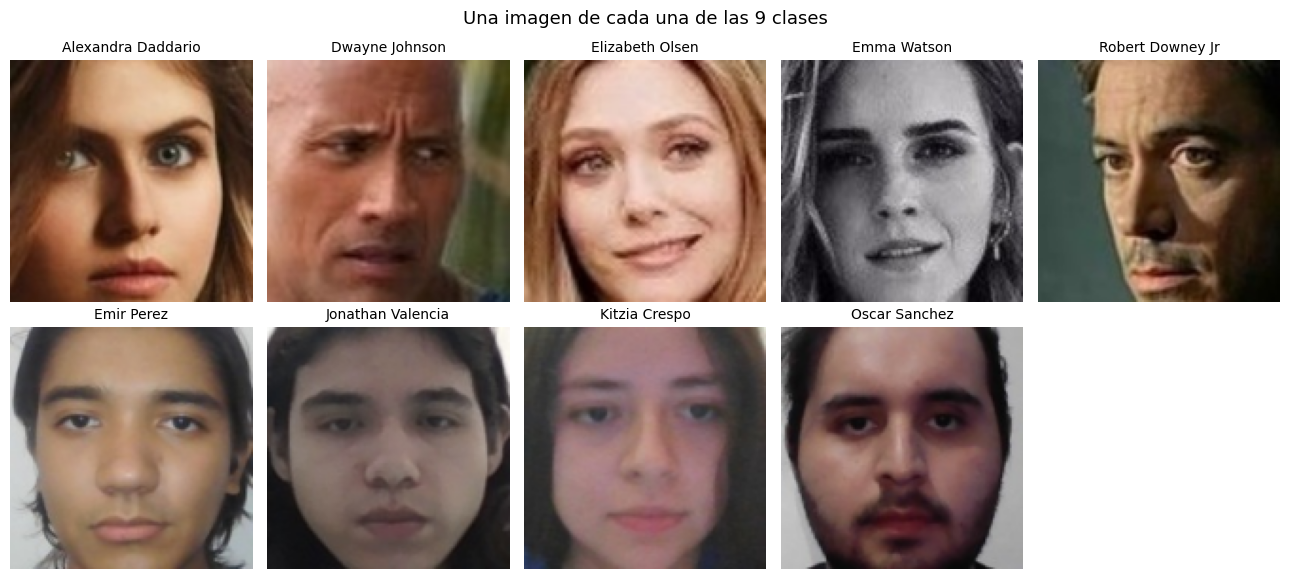

In [4]:
plt.figure(figsize=(13, 6))
for i, clase in enumerate(CLASES):
    primera = int(np.where(y == i)[0][0])
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[primera])
    plt.title(clase.replace("_", " "), fontsize=10)
    plt.axis("off")
plt.suptitle("Una imagen de cada una de las " + str(len(CLASES)) + " clases", fontsize=13)
plt.tight_layout()
plt.show()

#### Análisis de iluminación y nitidez por clase

Antes de entrenar conviene medir el brillo, el contraste y la nitidez de cada
clase. Si una persona se distingue de las demás por algo que no es su cara, la
red va a aprovechar ese atajo en lugar de aprenderse los rasgos, y después
fallará frente a la cámara.

La nitidez se mide con la varianza del laplaciano, un número chico cuando la
imagen está borrosa y grande cuando tiene bordes marcados.

In [5]:
def estadisticas_por_clase(imagenes, etiquetas, clases):
    """
    Mide el brillo, el contraste y la nitidez de las imágenes de cada clase.

    Se usa la mediana y no el promedio para que una sola foto rara no mueva
    el resultado de toda la clase.
    """
    print("%-22s %10s %11s %10s" % ("Clase", "Brillo", "Contraste", "Nitidez"))
    for i, clase in enumerate(clases):
        grises = [cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) for img in imagenes[etiquetas == i]]
        brillo = np.median([g.mean() for g in grises])
        contraste = np.median([g.std() for g in grises])
        nitidez = np.median([cv2.Laplacian(g, cv2.CV_64F).var() for g in grises])
        print("%-22s %10.0f %11.0f %10.0f"
              % (clase.replace("_", " "), brillo, contraste, nitidez))


estadisticas_por_clase(X, y, CLASES)

Clase                      Brillo   Contraste    Nitidez
Alexandra Daddario            131          62        199
Dwayne Johnson                125          50        222
Elizabeth Olsen               135          58        260
Emma Watson                   123          55        154
Robert Downey Jr              124          62        254
Emir Perez                    120          42        209


Jonathan Valencia              90          41         88
Kitzia Crespo                  95          40         53
Oscar Sanchez                 127          57        244


El análisis del brillo y la nitidez permitió identificar diferencias
en las condiciones de captura de los integrantes del equipo, debido
al uso de distintas cámaras y condiciones de iluminación.

Para favorecer el aprendizaje de las características faciales y
reducir la dependencia de estos factores, se aplican técnicas de
aumento de datos. Además, se realiza una prueba de robustez para
evaluar la capacidad de generalización del modelo ante distintas
condiciones de captura.

### 4. División estratificada del dataset en entrenamiento y validación

De acuerdo con las instrucciones de la práctica, el dataset se
divide únicamente en dos conjuntos: entrenamiento y validación.
Se omite el conjunto de prueba tradicional, ya que la evaluación
principal se realiza mediante el reconocimiento facial en tiempo
real.

La división se realiza de forma estratificada, utilizando el 80 %
de las imágenes de cada clase para el entrenamiento y el 20 % para
la validación. De esta manera, las nueve personas mantienen la
misma proporción en ambos conjuntos.

Las etiquetas se convierten al formato *One-Hot Encoding*, en el
cual cada clase se representa mediante un vector de nueve posiciones,
con un valor de 1 en la clase correspondiente y 0 en las restantes.
Este formato permite utilizar la función de pérdida
`categorical_crossentropy` para la clasificación multiclase.

In [6]:
def dividir_estratificado(etiquetas, proporcion, semilla):
    """
    Separa los índices en entrenamiento y validación respetando la proporción
    dentro de cada clase, para que ninguna quede desbalanceada.
    """
    generador = np.random.default_rng(semilla)
    entrenamiento = []
    validacion = []

    for clase in np.unique(etiquetas):
        indices = np.where(etiquetas == clase)[0]
        generador.shuffle(indices)
        corte = int(len(indices) * proporcion)
        entrenamiento.extend(indices[:corte])
        validacion.extend(indices[corte:])

    entrenamiento = np.array(entrenamiento)
    validacion = np.array(validacion)
    generador.shuffle(entrenamiento)
    generador.shuffle(validacion)
    return entrenamiento, validacion


indices_entrenamiento, indices_validacion = dividir_estratificado(
    y, PROPORCION_ENTRENAMIENTO, SEMILLA)

X_entrenamiento = X[indices_entrenamiento]
X_validacion = X[indices_validacion]

y_entrenamiento = y[indices_entrenamiento]
y_validacion = y[indices_validacion]

Y_entrenamiento = keras.utils.to_categorical(y_entrenamiento, len(CLASES))
Y_validacion = keras.utils.to_categorical(y_validacion, len(CLASES))

print("Entrenamiento %3d imágenes" % len(X_entrenamiento))
print("Validación    %3d imágenes" % len(X_validacion))
print()
print("Imágenes de cada clase en cada conjunto")
for i, clase in enumerate(CLASES):
    print("   %-22s entrenamiento %2d   validación %2d"
          % (clase, int((y_entrenamiento == i).sum()), int((y_validacion == i).sum())))

Entrenamiento 720 imágenes
Validación    180 imágenes

Imágenes de cada clase en cada conjunto
   Alexandra_Daddario     entrenamiento 80   validación 20
   Dwayne_Johnson         entrenamiento 80   validación 20
   Elizabeth_Olsen        entrenamiento 80   validación 20
   Emma_Watson            entrenamiento 80   validación 20
   Robert_Downey_Jr       entrenamiento 80   validación 20
   Emir_Perez             entrenamiento 80   validación 20
   Jonathan_Valencia      entrenamiento 80   validación 20
   Kitzia_Crespo          entrenamiento 80   validación 20
   Oscar_Sanchez          entrenamiento 80   validación 20


### 5. Preprocesamiento de imágenes: normalización y aumento de datos

La normalización y el aumento de datos se implementan mediante
capas que se integran directamente en el modelo, de acuerdo con
los requisitos de la práctica.

**Normalización.** La capa `Rescaling` divide los valores de los
píxeles entre 255 para ajustar su escala al rango de 0 a 1.
Al integrar esta operación en el modelo, no es necesario
normalizar nuevamente las imágenes capturadas por OpenCV
durante el reconocimiento facial en tiempo real.

**Aumento de datos.** Las capas de Data Augmentation generan
variaciones aleatorias de las imágenes durante cada época
del entrenamiento. Estas transformaciones no se aplican
durante la validación ni la inferencia.

Se utilizan dos grupos de transformaciones, cada uno con
una finalidad diferente:

Las transformaciones de **posición**, como el volteo horizontal,
la rotación, el acercamiento y el desplazamiento, permiten que
la red aprenda a reconocer un mismo rostro desde diferentes
ángulos y posiciones.

Las transformaciones de **apariencia**, como los ajustes de
brillo, contraste, desenfoque y nitidez, permiten reducir la
dependencia del modelo respecto a las condiciones de captura.
De esta manera, se favorece el aprendizaje de las características
faciales en lugar de las diferencias de iluminación y nitidez
entre las imágenes de cada clase.

In [7]:
aumento_de_datos = keras.Sequential([
    # Cambios de posición

    # Voltea la imagen horizontalmente, una cara volteada sigue siendo la misma
    layers.RandomFlip("horizontal"),
    # Gira la imagen hasta un 8 % de una vuelta completa
    layers.RandomRotation(0.08),
    # Acerca o aleja la imagen hasta un 12 %
    layers.RandomZoom(0.12),
    # Recorre la imagen hasta un 8 % de su alto y de su ancho
    layers.RandomTranslation(0.08, 0.08),

    # Cambios de apariencia, los que quitan el atajo del brillo y la nitidez

    # Aclara u oscurece la imagen para imitar distintas iluminaciones
    layers.RandomBrightness(0.35, value_range=(0, 255)),
    # Sube o baja el contraste
    layers.RandomContrast(0.35),
    # Desenfoca la imagen, como si la cámara perdiera el foco
    layers.RandomGaussianBlur(factor=(0.0, 1.5)),
    # Marca más los bordes, como si la cámara fuera de mejor calidad
    layers.RandomSharpness(factor=0.6, value_range=(0, 255)),
], name="aumento_de_datos")

print("Capas de aumento de datos")
for capa in aumento_de_datos.layers:
    print("   ", capa.name)

Capas de aumento de datos
    random_flip
    random_rotation
    random_zoom
    random_translation
    random_brightness
    random_contrast
    random_gaussian_blur
    random_sharpness


#### Visualización de las transformaciones del aumento de datos

Se toma una sola imagen del conjunto de entrenamiento y se pasa ocho veces por
las capas de aumento. Cada resultado es distinto, y esas son las variantes que
la red irá viendo a lo largo de las épocas.

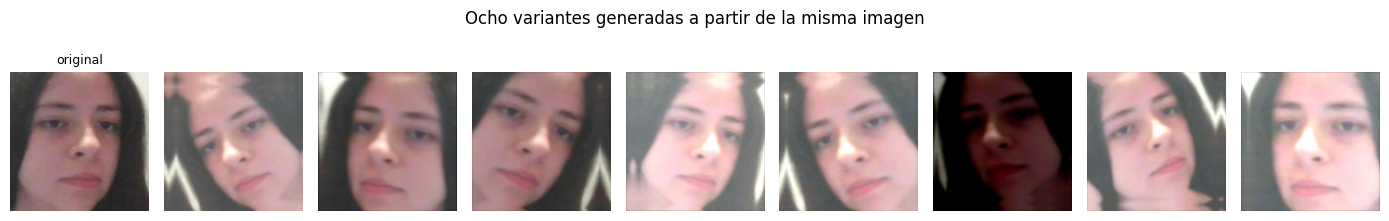

In [8]:
ejemplo = X_entrenamiento[0:1].astype("float32")

plt.figure(figsize=(14, 2.4))
plt.subplot(1, 9, 1)
plt.imshow(X_entrenamiento[0])
plt.title("original", fontsize=9)
plt.axis("off")

for i in range(8):
    variante = aumento_de_datos(ejemplo, training=True)
    plt.subplot(1, 9, i + 2)
    plt.imshow(np.clip(variante[0].numpy(), 0, 255).astype("uint8"))
    plt.axis("off")

plt.suptitle("Ocho variantes generadas a partir de la misma imagen", fontsize=12)
plt.tight_layout()
plt.show()

## II. Arquitectura de la red neuronal convolucional (CNN)

### 6. Diseño y arquitectura de la red neuronal convolucional desde cero

La red se construye desde cero con cuatro bloques convolucionales. Cada bloque
repite el mismo patrón:

1. **`Conv2D`** aplica filtros de 3 × 3 que recorren la imagen para
   extraer características visuales. Los primeros bloques identifican
   patrones simples, como bordes y cambios de color, mientras que los
   últimos reconocen características más complejas, como la forma
   de los ojos o de la boca.

2. **`BatchNormalization`** normaliza los valores obtenidos de la
   convolución para favorecer la estabilidad del entrenamiento.
   Se reduce el valor de `momentum` de 0.99 a 0.9 para actualizar
   con mayor rapidez las estadísticas utilizadas durante la validación,
   debido a que cada época contiene únicamente 23 lotes.

3. **`MaxPooling2D`** selecciona el valor máximo de cada región de
   2 × 2, lo que reduce las dimensiones espaciales a la mitad,
   conserva las características más relevantes y disminuye el
   costo computacional.

La cantidad de filtros aumenta progresivamente (32, 64, 128 y 128),
mientras que las dimensiones espaciales se reducen de 128 × 128
a 64 × 64, 32 × 32, 16 × 16 y 8 × 8 píxeles.

Al finalizar el último bloque convolucional, se utiliza la capa
**`GlobalAveragePooling2D`** en lugar de `Flatten`. En vez de convertir
los 8 × 8 × 128 valores en un vector de 8192 elementos, se calcula
el promedio de cada mapa de características para obtener únicamente
128 valores. Esto reduce considerablemente la cantidad de pesos
y ayuda a evitar que la red aprenda de memoria el dataset.

Las capas **`Dropout`** desactivan temporalmente y de forma aleatoria
una parte de las neuronas durante el entrenamiento, un 40 % en la
primera y un 30 % en la segunda, lo cual es una técnica de
regularización que permite que la red no dependa siempre de las
mismas neuronas, lo que ayuda a prevenir el sobreajuste y a mejorar
la clasificación de imágenes nuevas.

La última capa contiene una neurona por persona y utiliza la función
de activación **`softmax`**, que distribuye el 100 % de las probabilidades
de clasificación entre las nueve clases. La probabilidad más alta
se muestra como porcentaje de confianza sobre cada rostro durante
el reconocimiento facial en tiempo real.

In [9]:
def construir_cnn(lado, cantidad_clases):
    """
    Arma la red neuronal convolucional desde cero.

    Cada bloque hace lo mismo, una convolución que busca características, una
    normalización que estabiliza los valores y un agrupamiento que reduce la
    imagen a la mitad.
    """
    modelo = keras.Sequential([
        keras.Input(shape=(lado, lado, 3)),

        # Genera variantes de la imagen, solo durante el entrenamiento
        aumento_de_datos,

        # Lleva los píxeles del rango de 0 a 255 al rango de 0 a 1
        layers.Rescaling(1.0 / 255),

        # Bloque 1, de 128 a 64 píxeles
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        # Bloque 2, de 64 a 32 píxeles
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        # Bloque 3, de 32 a 16 píxeles
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        # Bloque 4, de 16 a 8 píxeles
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(),

        # Promedia cada filtro y deja un solo número por filtro
        layers.GlobalAveragePooling2D(),

        # Clasificador final
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(cantidad_clases, activation="softmax"),
    ], name="cnn_rostros")

    return modelo


modelo_cnn = construir_cnn(LADO, len(CLASES))
modelo_cnn.summary()

Model: "cnn_rostros"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 259,913 (1015.29 KB)

 Trainable params: 259,209 (1012.54 KB)

 Non-trainable params: 704 (2.75 KB)

## III. Entrenamiento y evaluación de los modelos

### 7. Compilación del modelo y configuración de callbacks

**Optimizador.** Se utiliza **Adam** con una tasa de aprendizaje
(*learning rate*) inicial de 0.001, que controla la magnitud
de los ajustes realizados en los pesos durante el entrenamiento.

**Función de pérdida.** Se utiliza **categorical_crossentropy**,
de acuerdo con las instrucciones de la práctica para la
clasificación multiclase. Esta función mide la diferencia
entre las probabilidades obtenidas por la red y las etiquetas
correctas.

**Callbacks.** Son funciones que Keras ejecuta al finalizar
cada época para monitorear y ajustar el proceso de entrenamiento.

| Callback | Función |
| --- | --- |
| **ModelCheckpoint** | Guarda el modelo cada vez que mejora la precisión de validación para conservar la mejor versión obtenida. |
| **EarlyStopping** | Detiene el entrenamiento después de 18 épocas consecutivas sin mejora y recupera los mejores pesos. |
| **ReduceLROnPlateau** | Reduce la tasa de aprendizaje a la mitad cuando la pérdida de validación deja de mejorar, con la finalidad de realizar ajustes más pequeños en los pesos. |

In [10]:
modelo_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

ARCHIVO_CNN = "mejor_cnn_desde_cero.keras"

callbacks_cnn = [
    # Conserva en el disco la versión con mejor precisión de validación
    keras.callbacks.ModelCheckpoint(ARCHIVO_CNN, monitor="val_accuracy",
                                    save_best_only=True),
    # Detiene el entrenamiento cuando deja de mejorar
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=18,
                                  restore_best_weights=True, verbose=1),
    # Afina con pasos más chicos cuando la pérdida se estanca
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=6, min_lr=0.00001, verbose=1),
]

print("Modelo compilado con", len(callbacks_cnn), "callbacks")

Modelo compilado con 3 callbacks


### 8. Entrenamiento de la red neuronal convolucional

Se establece un máximo de 70 épocas de entrenamiento, aunque
el callback **EarlyStopping** puede detener el proceso antes
si el modelo deja de mejorar.

En una computadora que utiliza únicamente la CPU, cada época
tarda aproximadamente 15 segundos, con un tiempo total estimado
de 15 a 20 minutos. Este tiempo puede reducirse si se utiliza
una GPU compatible con TensorFlow.

In [11]:
historial_cnn = modelo_cnn.fit(
    X_entrenamiento, Y_entrenamiento,
    validation_data=(X_validacion, Y_validacion),
    epochs=EPOCAS,
    batch_size=TAMANO_LOTE,
    callbacks=callbacks_cnn,
    verbose=2,
)

print()
print("Épocas realizadas", len(historial_cnn.history["loss"]))
print("Mejor precisión de validación %.4f" % max(historial_cnn.history["val_accuracy"]))

Epoch 1/70


23/23 - 34s - 1s/step - accuracy: 0.3139 - loss: 2.0636 - val_accuracy: 0.1444 - val_loss: 3.5702 - learning_rate: 0.0010


Epoch 2/70


23/23 - 27s - 1s/step - accuracy: 0.4528 - loss: 1.5337 - val_accuracy: 0.4167 - val_loss: 1.8759 - learning_rate: 0.0010


Epoch 3/70


23/23 - 22s - 955ms/step - accuracy: 0.5194 - loss: 1.3685 - val_accuracy: 0.4667 - val_loss: 1.3035 - learning_rate: 0.0010


... (130 outputs left out)

23/23 - 21s - 897ms/step - accuracy: 0.8542 - loss: 0.3767 - val_accuracy: 0.8556 - val_loss: 0.4337 - learning_rate: 3.1250e-05


Epoch 66: early stopping


Restoring model weights from the end of the best epoch: 48.



Épocas realizadas 66
Mejor precisión de validación 0.8722


### 9. Monitoreo y análisis de las curvas de pérdida y precisión

Se monitorean las curvas de pérdida y precisión de los conjuntos
de entrenamiento y validación para conocer el desempeño de la
red y su capacidad de generalización, es decir, qué tan bien
clasifica imágenes que no ha visto anteriormente.

- Si la precisión de ambos conjuntos aumenta y sus curvas se
  mantienen cercanas, es una señal de que la red está aprendiendo
  a generalizar correctamente.

- Si la precisión de entrenamiento continúa aumentando, pero la
  de validación se estanca o disminuye, puede existir sobreajuste.
  Esto ocurre cuando la red se adapta demasiado a las imágenes
  de entrenamiento y presenta dificultades para reconocer rostros
  en imágenes nuevas.

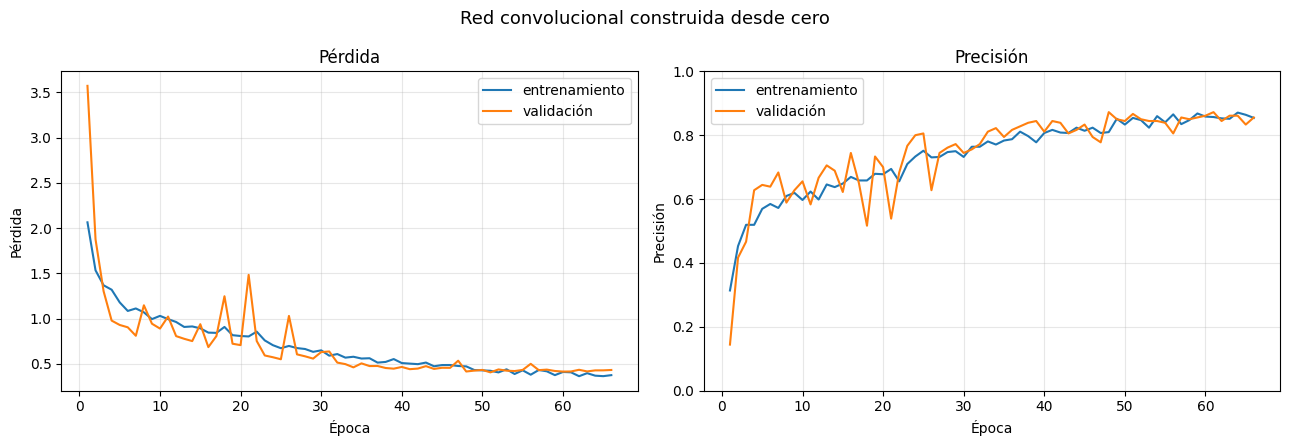

In [12]:
def graficar_curvas(historial, titulo):
    """Dibuja la pérdida y la precisión de entrenamiento y de validación."""
    datos = historial.history
    epocas = range(1, len(datos["loss"]) + 1)

    figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

    ejes[0].plot(epocas, datos["loss"], label="entrenamiento")
    ejes[0].plot(epocas, datos["val_loss"], label="validación")
    ejes[0].set_title("Pérdida")
    ejes[0].set_xlabel("Época")
    ejes[0].set_ylabel("Pérdida")
    ejes[0].legend()
    ejes[0].grid(alpha=0.3)

    ejes[1].plot(epocas, datos["accuracy"], label="entrenamiento")
    ejes[1].plot(epocas, datos["val_accuracy"], label="validación")
    ejes[1].set_title("Precisión")
    ejes[1].set_xlabel("Época")
    ejes[1].set_ylabel("Precisión")
    ejes[1].set_ylim(0, 1)
    ejes[1].legend()
    ejes[1].grid(alpha=0.3)

    figura.suptitle(titulo, fontsize=13)
    figura.tight_layout()
    plt.show()


graficar_curvas(historial_cnn, "Red convolucional construida desde cero")

### 10. Evaluación de la clasificación por clase mediante la matriz de confusión

La precisión general indica qué tan bien clasifica la red
las imágenes, pero no especifica en qué clases se producen
los errores. Para analizar estos resultados, se utiliza
una **matriz de confusión**.

Cada fila representa la clase real de la imagen y cada
columna corresponde a la clase predicha por el modelo.
Los valores de la diagonal principal representan las
clasificaciones correctas, mientras que los valores fuera
de ella indican confusiones entre distintas personas.

El modelo presenta un desempeño favorable en la clasificación de
rostros, especialmente en los integrantes del equipo. Aunque el
dataset está balanceado, con 100 imágenes por clase, las fotografías
de las personas famosas presentan una mayor variedad de edades,
peinados, maquillaje y condiciones de iluminación, lo que representa
un mayor desafío para el aprendizaje de sus características faciales.

Pérdida de validación   0.4169
Precisión de validación 0.8722

Persona                  Imágenes     Aciertos    Confianza
Alexandra Daddario             20        90.0 %       0.713
Dwayne Johnson                 20        85.0 %       0.811
Elizabeth Olsen                20        70.0 %       0.628
Emma Watson                    20        50.0 %       0.606
Robert Downey Jr               20        90.0 %       0.725
Emir Perez                     20       100.0 %       1.000
Jonathan Valencia              20       100.0 %       0.999
Kitzia Crespo                  20       100.0 %       0.998
Oscar Sanchez                  20       100.0 %       1.000

Total                         180        87.2 %       0.831


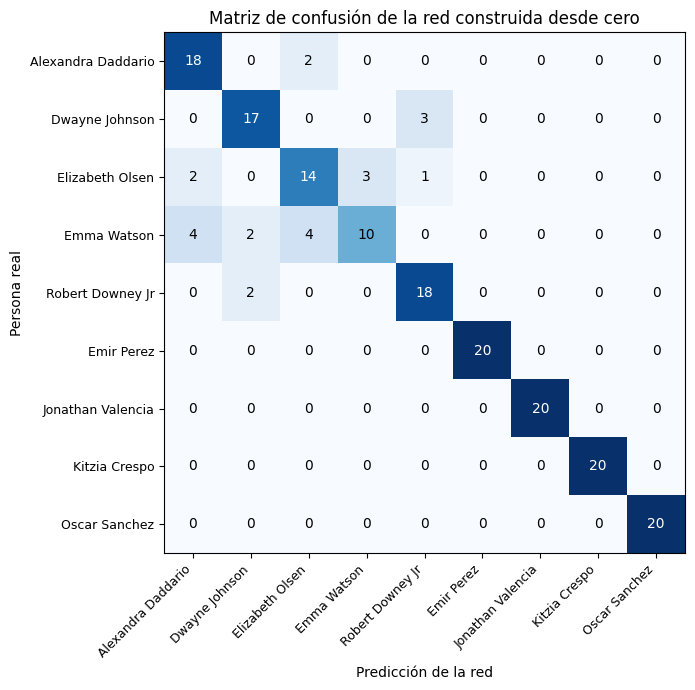

In [13]:
def matriz_de_confusion(reales, predichas, cantidad):
    """Cuenta cuántas veces cada clase real se predijo como cada clase."""
    matriz = np.zeros((cantidad, cantidad), dtype=int)
    for real, predicha in zip(reales, predichas):
        matriz[int(real), int(predicha)] += 1
    return matriz


def graficar_matriz(matriz, clases, titulo):
    """Dibuja la matriz de confusión con el número dentro de cada casilla."""
    figura, eje = plt.subplots(figsize=(8.5, 7))
    eje.imshow(matriz, cmap="Blues")

    nombres = [c.replace("_", " ") for c in clases]
    eje.set_xticks(range(len(clases)), nombres, rotation=45, ha="right", fontsize=9)
    eje.set_yticks(range(len(clases)), nombres, fontsize=9)
    eje.set_xlabel("Predicción de la red")
    eje.set_ylabel("Persona real")
    eje.set_title(titulo)

    limite = matriz.max() / 2.0
    for i in range(len(clases)):
        for j in range(len(clases)):
            color = "white" if matriz[i, j] > limite else "black"
            eje.text(j, i, str(matriz[i, j]), ha="center", va="center", color=color)

    figura.tight_layout()
    plt.show()


def reporte_por_clase(reales, probabilidades, clases):
    """Muestra cuántas acertó la red en cada clase y con cuánta confianza."""
    predichas = probabilidades.argmax(axis=1)
    print("%-22s %10s %12s %12s" % ("Persona", "Imágenes", "Aciertos", "Confianza"))
    for i, clase in enumerate(clases):
        cuales = reales == i
        aciertos = (predichas[cuales] == i).mean()
        confianza = probabilidades[cuales].max(axis=1).mean()
        print("%-22s %10d %11.1f %% %11.3f"
              % (clase.replace("_", " "), int(cuales.sum()), aciertos * 100, confianza))
    print()
    print("%-22s %10d %11.1f %% %11.3f"
          % ("Total", len(reales), (predichas == reales).mean() * 100,
             probabilidades.max(axis=1).mean()))


probabilidades_cnn = modelo_cnn.predict(X_validacion, verbose=0)
perdida_cnn, precision_cnn = modelo_cnn.evaluate(X_validacion, Y_validacion, verbose=0)

print("Pérdida de validación   %.4f" % perdida_cnn)
print("Precisión de validación %.4f" % precision_cnn)
print()
reporte_por_clase(y_validacion, probabilidades_cnn, CLASES)

graficar_matriz(matriz_de_confusion(y_validacion, probabilidades_cnn.argmax(axis=1),
                                    len(CLASES)),
                CLASES, "Matriz de confusión de la red construida desde cero")

### 11. Implementación de Transfer Learning con MobileNetV2

La práctica contempla dos alternativas: diseñar una red neuronal
convolucional desde cero o utilizar Transfer Learning. Por ello,
se implementan ambas arquitecturas para comparar su desempeño
con el mismo dataset.

El **Transfer Learning** (aprendizaje por transferencia) consiste
en reutilizar los conocimientos adquiridos por una red previamente
entrenada. En este caso, se utiliza **MobileNetV2**, entrenada con
el dataset ImageNet, que ya ha aprendido a identificar características
visuales como bordes, texturas y formas.

Se congelan las capas de la red preentrenada para conservar sus
pesos originales y se agrega una nueva capa de salida con nueve
neuronas, una por cada clase. De esta manera, solo se ajustan
los pesos del nuevo clasificador, lo que reduce el tiempo y el
costo computacional del entrenamiento.

A diferencia de la CNN construida desde cero, MobileNetV2 requiere
que los valores de los píxeles se encuentren en el rango de -1 a 1,
en lugar de 0 a 1. Por esta razón, se modifica la configuración
de la capa **Rescaling**.

In [14]:
base_mobilenet = keras.applications.MobileNetV2(
    input_shape=(LADO, LADO, 3),
    include_top=False,
    weights="imagenet",
)

# Se congela la parte preentrenada, solo se entrenará la capa final
base_mobilenet.trainable = False

modelo_mobilenet = keras.Sequential([
    keras.Input(shape=(LADO, LADO, 3)),
    aumento_de_datos,
    # MobileNetV2 espera los píxeles entre -1 y 1
    layers.Rescaling(1.0 / 127.5, offset=-1),
    base_mobilenet,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(CLASES), activation="softmax"),
], name="mobilenet_rostros")

modelo_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

ARCHIVO_MOBILENET = "mejor_mobilenet.keras"

callbacks_mobilenet = [
    keras.callbacks.ModelCheckpoint(ARCHIVO_MOBILENET, monitor="val_accuracy",
                                    save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                  restore_best_weights=True, verbose=1),
]

modelo_mobilenet.summary()

Model: "mobilenet_rostros"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
historial_mobilenet = modelo_mobilenet.fit(
    X_entrenamiento, Y_entrenamiento,
    validation_data=(X_validacion, Y_validacion),
    epochs=30,
    batch_size=TAMANO_LOTE,
    callbacks=callbacks_mobilenet,
    verbose=2,
)

print()
print("Épocas realizadas", len(historial_mobilenet.history["loss"]))
print("Mejor precisión de validación %.4f" % max(historial_mobilenet.history["val_accuracy"]))

Epoch 1/30


23/23 - 19s - 821ms/step - accuracy: 0.2444 - loss: 2.1071 - val_accuracy: 0.5722 - val_loss: 1.4427


Epoch 2/30


23/23 - 9s - 403ms/step - accuracy: 0.5208 - loss: 1.4215 - val_accuracy: 0.6778 - val_loss: 0.9521


Epoch 3/30


23/23 - 9s - 407ms/step - accuracy: 0.6611 - loss: 1.0267 - val_accuracy: 0.7500 - val_loss: 0.7689


... (33 outputs left out)

23/23 - 9s - 379ms/step - accuracy: 0.8611 - loss: 0.3999 - val_accuracy: 0.8889 - val_loss: 0.3385


Epoch 20: early stopping


Restoring model weights from the end of the best epoch: 12.



Épocas realizadas 20
Mejor precisión de validación 0.9111


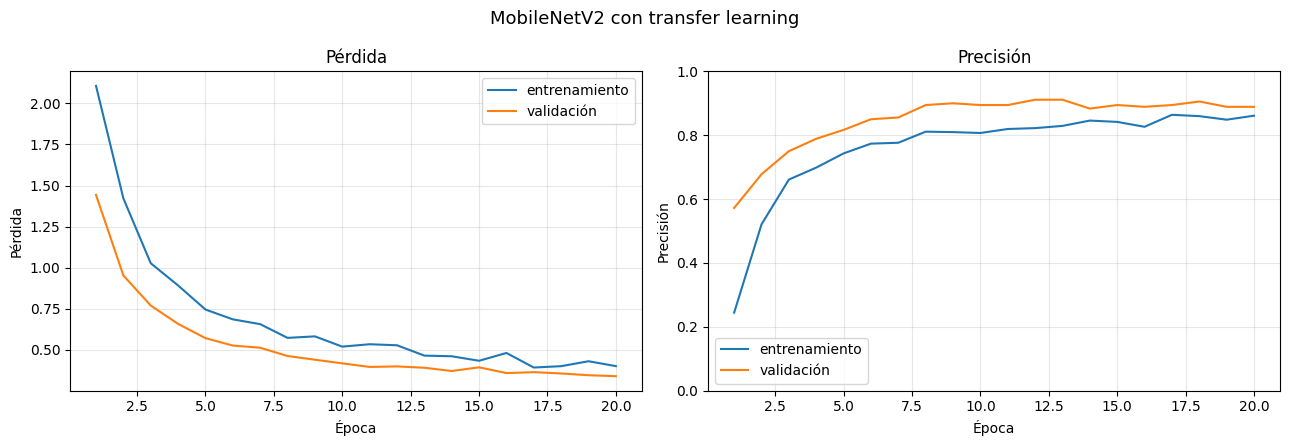

Pérdida de validación   0.3982
Precisión de validación 0.9111

Persona                  Imágenes     Aciertos    Confianza
Alexandra Daddario             20        95.0 %       0.770
Dwayne Johnson                 20        90.0 %       0.695
Elizabeth Olsen                20        75.0 %       0.618
Emma Watson                    20        65.0 %       0.583
Robert Downey Jr               20        95.0 %       0.711
Emir Perez                     20       100.0 %       0.990
Jonathan Valencia              20       100.0 %       0.973
Kitzia Crespo                  20       100.0 %       0.943
Oscar Sanchez                  20       100.0 %       0.933

Total                         180        91.1 %       0.802


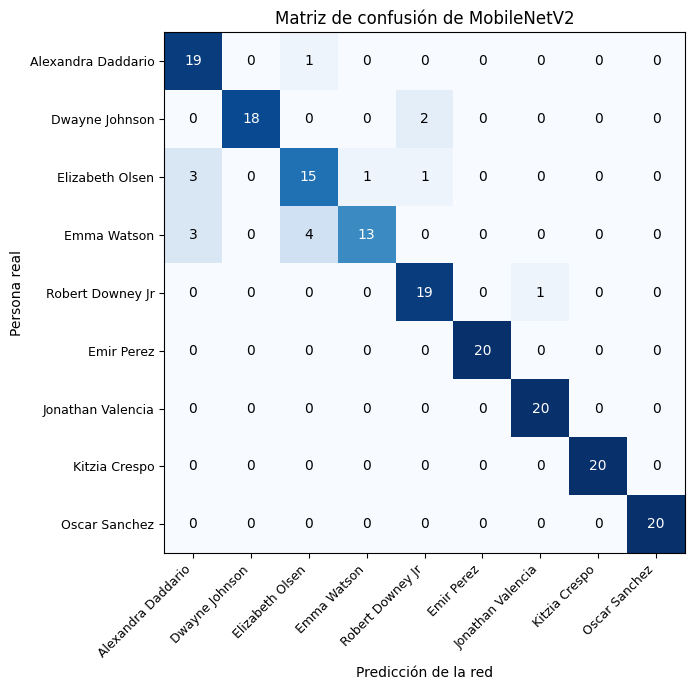

In [16]:
graficar_curvas(historial_mobilenet, "MobileNetV2 con transfer learning")

probabilidades_mobilenet = modelo_mobilenet.predict(X_validacion, verbose=0)
perdida_mobilenet, precision_mobilenet = modelo_mobilenet.evaluate(
    X_validacion, Y_validacion, verbose=0)

print("Pérdida de validación   %.4f" % perdida_mobilenet)
print("Precisión de validación %.4f" % precision_mobilenet)
print()
reporte_por_clase(y_validacion, probabilidades_mobilenet, CLASES)

graficar_matriz(matriz_de_confusion(y_validacion,
                                    probabilidades_mobilenet.argmax(axis=1), len(CLASES)),
                CLASES, "Matriz de confusión de MobileNetV2")

### 12. Prueba de robustez ante variaciones de iluminación y nitidez

La precisión de validación puede ser superior al desempeño real
del modelo debido a las condiciones de captura del dataset.

Las 100 fotografías de cada integrante se capturaron durante
una misma sesión, con condiciones similares de iluminación y
enfoque. Al dividir el dataset de forma aleatoria, ambos conjuntos
contienen imágenes muy similares. Por esta razón, la red puede
obtener buenos resultados en validación y presentar dificultades
durante el reconocimiento facial en tiempo real.

Para evaluar la capacidad de generalización del modelo, se realiza
una **validación difícil**, en la que se modifican intencionalmente
el brillo y la nitidez de las imágenes de validación para simular
diferentes condiciones de captura. Esta prueba permite analizar si
la red ha aprendido a reconocer las características faciales o si
depende demasiado de factores como la iluminación y la nitidez de
las imágenes.

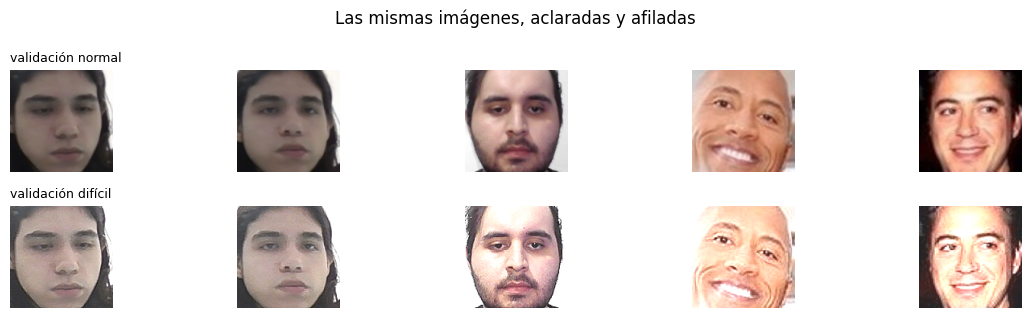

In [17]:
def volver_dificiles(imagenes):
    """
    Aclara y afila las imágenes para imitar lo que entrega la cámara en vivo.

    El filtro de afilado marca los bordes y convertScaleAbs sube el brillo y
    el contraste, que son justo las dos diferencias que se midieron entre las
    clases al cargar el dataset.
    """
    nucleo = np.array([[0, -1, 0],
                       [-1, 5, -1],
                       [0, -1, 0]], dtype=np.float32)
    salida = []
    for imagen in imagenes:
        afilada = cv2.filter2D(imagen, -1, nucleo)
        salida.append(cv2.convertScaleAbs(afilada, alpha=1.15, beta=35))
    return np.array(salida, dtype="float32")


X_dificil = volver_dificiles(X_validacion)

plt.figure(figsize=(12, 3.2))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_validacion[i])
    plt.axis("off")
    if i == 0:
        plt.title("validación normal", fontsize=9, loc="left")
    plt.subplot(2, 5, i + 6)
    plt.imshow(X_dificil[i].astype("uint8"))
    plt.axis("off")
    if i == 0:
        plt.title("validación difícil", fontsize=9, loc="left")
plt.suptitle("Las mismas imágenes, aclaradas y afiladas", fontsize=12)
plt.tight_layout()
plt.show()

In [18]:
def precision_en(modelo, imagenes, reales):
    """Devuelve qué proporción de imágenes acierta el modelo."""
    predichas = modelo.predict(imagenes, verbose=0).argmax(axis=1)
    return float((predichas == reales).mean())


dificil_cnn = precision_en(modelo_cnn, X_dificil, y_validacion)
dificil_mobilenet = precision_en(modelo_mobilenet, X_dificil, y_validacion)

print("%-14s %14s %14s %12s" % ("Modelo", "Normal", "Difícil", "Lo que baja"))
for nombre, normal, dificil in [("Desde cero", precision_cnn, dificil_cnn),
                                ("MobileNetV2", precision_mobilenet, dificil_mobilenet)]:
    print("%-14s %13.1f %% %13.1f %% %11.1f puntos"
          % (nombre, normal * 100, dificil * 100, (normal - dificil) * 100))

Modelo                 Normal        Difícil  Lo que baja
Desde cero              87.2 %          38.3 %        48.9 puntos
MobileNetV2             91.1 %          80.6 %        10.6 puntos


### 13. Comparación de arquitecturas y selección del mejor modelo

Se selecciona el modelo con mayor **precisión en la validación
difícil**, ya que esta prueba simula condiciones más cercanas
a las del reconocimiento facial en tiempo real.

En caso de empate, se considera la precisión obtenida en la
validación normal para determinar cuál modelo se guarda.

In [19]:
comparacion = [
    ("Desde cero", precision_cnn, dificil_cnn, perdida_cnn,
     float(probabilidades_cnn.max(axis=1).mean()), modelo_cnn,
     len(historial_cnn.history["loss"])),
    ("MobileNetV2", precision_mobilenet, dificil_mobilenet, perdida_mobilenet,
     float(probabilidades_mobilenet.max(axis=1).mean()), modelo_mobilenet,
     len(historial_mobilenet.history["loss"])),
]

print("%-14s %11s %10s %10s %11s %8s"
      % ("Modelo", "Normal", "Difícil", "Pérdida", "Confianza", "Épocas"))
for nombre, normal, dificil, perdida, confianza, _, epocas in comparacion:
    print("%-14s %10.2f %% %9.2f %% %10.4f %11.3f %8d"
          % (nombre, normal * 100, dificil * 100, perdida, confianza, epocas))

# Se escoge la que aguanta mejor la validación difícil
mejor = max(comparacion, key=lambda fila: (round(fila[2], 4), round(fila[1], 4)))
(nombre_mejor, precision_mejor, dificil_mejor, perdida_mejor,
 confianza_mejor, modelo_mejor, _) = mejor

print()
print("Modelo elegido", nombre_mejor)
print("Precisión normal  %.2f %%" % (precision_mejor * 100))
print("Precisión difícil %.2f %%" % (dificil_mejor * 100))

Modelo              Normal    Difícil    Pérdida   Confianza   Épocas
Desde cero          87.22 %     38.33 %     0.4169       0.831       66
MobileNetV2         91.11 %     80.56 %     0.3982       0.802       20

Modelo elegido MobileNetV2
Precisión normal  91.11 %
Precisión difícil 80.56 %


## IV. Implementación y demostración en tiempo real

### 14. Guardado del modelo entrenado y las etiquetas de clasificación

Se guardan los archivos **modelo_rostros.keras** y **clases.json**,
necesarios para el reconocimiento facial en tiempo real.

La red devuelve nueve probabilidades, una por cada clase,
identificadas mediante índices del 0 al 8. El archivo
**clases.json** relaciona cada índice con el nombre de la persona
correspondiente, por lo que debe conservar el mismo orden
de las clases utilizadas durante el entrenamiento.

In [20]:
ARCHIVO_MODELO = "modelo_rostros.keras"
ARCHIVO_CLASES = "clases.json"

modelo_mejor.save(ARCHIVO_MODELO)

datos_de_clases = {
    "clases": CLASES,
    "lado": LADO,
    "arquitectura": nombre_mejor,
    "precision_validacion": round(float(precision_mejor), 4),
    "precision_validacion_dificil": round(float(dificil_mejor), 4),
}

with open(ARCHIVO_CLASES, "w", encoding="utf-8") as archivo:
    json.dump(datos_de_clases, archivo, ensure_ascii=False, indent=2)

print("Modelo guardado en", ARCHIVO_MODELO,
      "%.1f KB" % (os.path.getsize(ARCHIVO_MODELO) / 1024))
print("Clases guardadas en", ARCHIVO_CLASES)
print()
print(json.dumps(datos_de_clases, ensure_ascii=False, indent=2))

Modelo guardado en modelo_rostros.keras 9556.4 KB
Clases guardadas en clases.json

{
  "clases": [
    "Alexandra_Daddario",
    "Dwayne_Johnson",
    "Elizabeth_Olsen",
    "Emma_Watson",
    "Robert_Downey_Jr",
    "Emir_Perez",
    "Jonathan_Valencia",
    "Kitzia_Crespo",
    "Oscar_Sanchez"
  ],
  "lado": 128,
  "arquitectura": "MobileNetV2",
  "precision_validacion": 0.9111,
  "precision_validacion_dificil": 0.8056
}


### 15. Verificación del modelo guardado mediante predicciones

Antes de implementar el reconocimiento facial en tiempo real,
se comprueba que el modelo se haya guardado correctamente.
Para ello, se vuelve a cargar desde el disco y se realizan
predicciones con algunas imágenes del conjunto de validación.

Sobre cada imagen se muestra el nombre de la persona identificada
y el porcentaje de confianza. Las clasificaciones correctas se
representan en verde y las incorrectas en rojo.

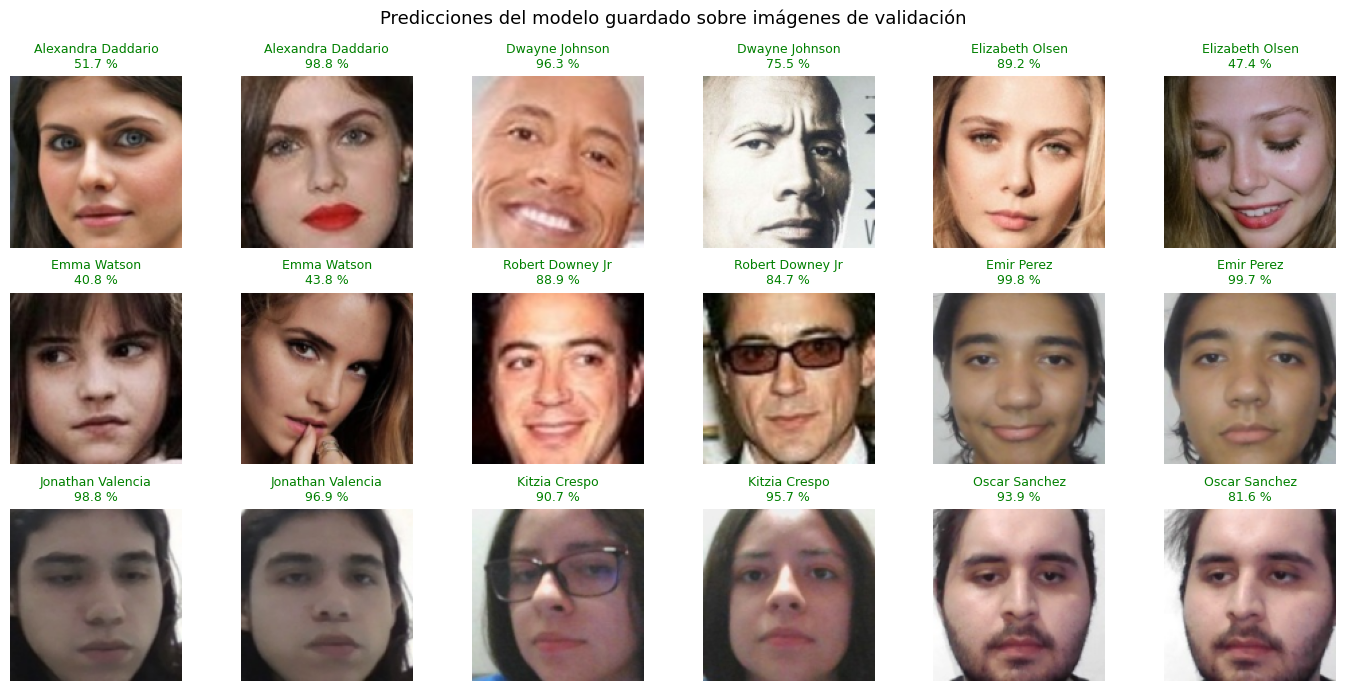

Aciertos en la muestra 18 de 18


In [21]:
modelo_cargado = keras.models.load_model(ARCHIVO_MODELO)

# Se toman dos imágenes de cada clase para que aparezcan todas las personas
muestra = []
for i in range(len(CLASES)):
    cuales = np.where(y_validacion == i)[0]
    muestra.extend(cuales[:2])
muestra = np.array(muestra)

probabilidades = modelo_cargado.predict(X_validacion[muestra], verbose=0)

plt.figure(figsize=(14, 7))
for posicion, indice in enumerate(muestra):
    predicha = int(probabilidades[posicion].argmax())
    confianza = float(probabilidades[posicion].max())
    acierto = predicha == y_validacion[indice]

    plt.subplot(3, 6, posicion + 1)
    plt.imshow(X_validacion[indice])
    plt.title("%s\n%.1f %%" % (CLASES[predicha].replace("_", " "), confianza * 100),
              fontsize=9, color="green" if acierto else "red")
    plt.axis("off")

plt.suptitle("Predicciones del modelo guardado sobre imágenes de validación", fontsize=13)
plt.tight_layout()
plt.show()

aciertos = int((probabilidades.argmax(axis=1) == y_validacion[muestra]).sum())
print("Aciertos en la muestra", aciertos, "de", len(muestra))

### 16. Implementación del reconocimiento facial en tiempo real con OpenCV

Con los archivos **modelo_rostros.keras** y **clases.json** en
la misma carpeta que el programa de Python, se ejecuta el
siguiente comando desde la terminal:

```bash
python reconocer-rostros.py
```

El programa utiliza OpenCV para acceder a la cámara web y
Haar Cascade para detectar los rostros. Posteriormente, cada
rostro se recorta y redimensiona para realizar la inferencia
con la red neuronal entrenada. Finalmente, se muestra una caja
delimitadora sobre cada rostro, junto con el nombre de la
persona identificada y el porcentaje de confianza.

## V. Conclusiones

Se completó el entrenamiento, la evaluación y la selección del
modelo, el cual se guardó junto con el archivo de clases para
su implementación en el reconocimiento facial en tiempo real.

Durante el entrenamiento se observaron los siguientes aspectos:

- **Precisión de validación.** Ambas arquitecturas obtuvieron
  resultados favorables durante la validación. Considerando que las
  100 fotografías de cada integrante se obtuvieron durante una misma
  sesión de captura y presentan condiciones similares de iluminación
  y nitidez, se complementó la evaluación con una prueba de robustez
  para analizar la capacidad de generalización de los modelos ante
  condiciones más cercanas a las del reconocimiento facial en tiempo real.

- **Aprendizaje de características.** El análisis del brillo y la
  nitidez de las imágenes permitió identificar diferencias en las
  condiciones de captura del dataset. A partir de este análisis,
  se aplicaron técnicas de aumento de datos para favorecer el
  aprendizaje de las características faciales y reducir la
  dependencia de las condiciones de iluminación y enfoque.

- **Desempeño del Transfer Learning.** MobileNetV2 obtuvo una
  precisión del 91.11 % en la validación normal y del 80.56 %
  en la validación difícil. Estos resultados reflejan una mayor
  capacidad de generalización ante cambios de iluminación y
  nitidez en comparación con la CNN construida desde cero.

- **Clasificación de rostros.** Se obtuvo un reconocimiento
  favorable de las nueve clases, con una precisión del 100 %
  en las imágenes de validación de los integrantes del equipo
  mediante MobileNetV2. Las fotografías de los famosos, obtenidas
  de Kaggle, representaron un mayor desafío debido a la variedad
  de edades, peinados y condiciones de iluminación.

### Posibles mejoras del dataset y del desempeño de los modelos

Aunque los modelos obtuvieron resultados favorables, el desempeño
podría mejorar al ampliar la cantidad y variedad de las imágenes
del dataset, con fotografías tomadas en diferentes momentos,
lugares y condiciones de iluminación. Esto contribuiría a fortalecer
la capacidad de generalización de ambas arquitecturas y a obtener
predicciones más estables durante el reconocimiento facial en tiempo real.